[![Text: CC BY-SA 4.0](https://img.shields.io/badge/text-CC%20BY--SA%204.0-lightgrey.svg)](https://creativecommons.org/licenses/by-sa/4.0/)
[![Code: MIT](https://img.shields.io/badge/code-MIT-yellow.svg)](https://opensource.org/license/mit)

This notebook is part of course materials for CS 545: Machine Learning at
Colorado State University. These notebooks are based on the PyTorch version of
[Dive into Deep Learning](https://d2l.ai) by Aston Zhang, Zachary C. Lipton,
Mu Li and Alexander J. Smola, used under
[CC BY-SA 4.0](https://creativecommons.org/licenses/by-sa/4.0/) and heavily
modified by [Asa Ben-Hur](https://www.cs.colostate.edu/~asa/) with
[Claude](https://claude.com) AI. The text is released under
[CC BY-SA 4.0](https://creativecommons.org/licenses/by-sa/4.0/); the code is
released under the [MIT license](https://opensource.org/license/mit).

# Training a GPT from Scratch

We have measured other people's language models. It's now time to build one!  We have everything we need: the decoder-only architecture and the method to evalute it (perplexity).  This notebook assembles those parts into a **Generative Pretrained Transformer (GPT)**, trains it on real text, and watches English emerge as training progresses.

Two decisions shape everything that follows.

**The corpus.**
Ordinary English text presumes a vast amount of world knowledge and vocabulary that a few-million-parameter model trained for twenty minutes cannot acquire.  **TinyStories** (Eldan & Li, 2023) was built to remove that mismatch: a synthetic corpus of short children's stories, generated by GPT-3.5/4 under the constraint that they use only the vocabulary a three-to-four-year-old understands.  Its authors showed that models with millions rather than billions of parameters produce fluent, coherent, grammatical stories when trained on it.  That makes it the rare corpus where a laptop-scale training run yields a model whose output is genuinely readable.

**The scale.**
Our default model is about 4M parameters trained on a few million tokens.  It will take a few minutes on Apple silicon, well under an hour on a CPU.  That is roughly 1/40,000th of GPT-3, and the point is not to compete.  The point is that the *recipe* is identical: the same architecture, objective, optimizer, and loss curve shape.  What separates our model from a frontier one is data, parameters, and compute - the three axes of the scaling laws we have seen in notebook 1.

The plan: prepare TinyStories, train a BPE tokenizer on it, build the model, verify it before training it, train while tracking validation perplexity, and generate stories from checkpoints along the way.

In [1]:
try:
    from matplotlib_inline.backend_inline import set_matplotlib_formats
    set_matplotlib_formats('svg')
except ImportError:
    pass

import math
import os
import time

import numpy as np
import torch
from torch import nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

BLUE, GREEN, IO = '#cdddec', '#d0e3d4', '#ededed'
AMBER, TX = '#c0662f', '#333333'

device = ('cuda' if torch.cuda.is_available()
          else 'mps' if torch.backends.mps.is_available() else 'cpu')
torch.manual_seed(0)
print(f'Using {device} device')

Using mps device


The following figure illustrates the pieces we need:  prepare the **data**, define the **model**, define the **objective** and associated training loop, and finally put the trained model to work.  
The targets are the inputs shifted by one position.  We report the model's **perplexity**, but it is not what the optimizer minimizes.

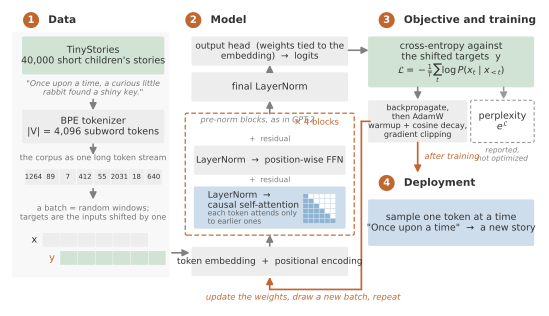

In [2]:
# a roadmap for this notebook: what we build, in what order
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch, Rectangle

GRAY = '#f8f8f8'

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.set_xlim(0, 112); ax.set_ylim(4, 74); ax.axis('off')

HDR, TOP = 71.0, 66.8   # heading baseline; top of each section's first box


def box(x, y, w, h, label, fc=IO, fs=9.5, ec='none', lw=0, ls='-'):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle='round,pad=0.4',
                                facecolor=fc, edgecolor=ec, linewidth=lw,
                                linestyle=ls))
    if label:
        ax.text(x + w / 2, y + h / 2, label, ha='center', va='center',
                fontsize=fs, color=TX)


def arrow(x1, y1, x2, y2, color='0.5', lw=1.6, ls='-'):
    ax.add_patch(FancyArrowPatch((x1, y1), (x2, y2), arrowstyle='-|>',
                                 mutation_scale=14, color=color, linewidth=lw,
                                 linestyle=ls, shrinkA=0, shrinkB=0))


def stage(x, n, text, y=None):
    y = HDR if y is None else y
    ax.text(x, y, n, ha='center', va='center', fontsize=10, color='white',
            fontweight='bold',
            bbox=dict(boxstyle='circle,pad=0.32', facecolor=AMBER, edgecolor='none'))
    ax.text(x + 3.6, y, text, ha='left', va='center', fontsize=10.5,
            color=TX, fontweight='bold')


# ============================== 1. DATA ===================================
ax.add_patch(Rectangle((1, 11.3), 33, 57, facecolor=GRAY, edgecolor='none', zorder=0))
stage(5, '1', 'Data')

box(3.5, 58.8, 29, 8, 'TinyStories\n40,000 short children\'s stories', fc=GREEN)
ax.text(18, 57.1, '"Once upon a time, a curious little\nrabbit found a shiny key."',
        ha='center', va='top', fontsize=7.8, style='italic', color='0.45')

arrow(18, 52.6, 18, 50.1)
box(3.5, 42.8, 29, 7, 'BPE tokenizer\n|V| = 4,096 subword tokens')

arrow(18, 42.2, 18, 39.7)
ax.text(18, 38.5, 'the corpus as one long token stream', ha='center',
        fontsize=8, color='0.45')
for i, t in enumerate(['1264', '89', '7', '412', '55', '2031', '18', '640']):
    ax.add_patch(FancyBboxPatch((3.9 + i * 3.6, 32.9), 3.2, 3.4,
                                boxstyle='round,pad=0.1', facecolor=IO,
                                edgecolor='none'))
    ax.text(5.5 + i * 3.6, 34.6, t, ha='center', va='center', fontsize=6.8,
            color=TX)

arrow(18, 31.9, 18, 29.4)
ax.text(18, 28.2, 'a batch = random windows;\ntargets are the inputs shifted by one',
        ha='center', va='top', fontsize=8, color='0.45')

# x / y windows, aligned on one grid so the one-position shift is exact
PITCH, CW, CH = 3.7, 3.4, 3.0
X0, XROW, YROW = 7.5, 18.5, 14.3
for i in range(6):
    ax.add_patch(FancyBboxPatch((X0 + i * PITCH, XROW), CW, CH,
                                boxstyle='round,pad=0.1', facecolor=IO,
                                edgecolor='none'))
    ax.add_patch(FancyBboxPatch((X0 + (i + 1) * PITCH, YROW), CW, CH,
                                boxstyle='round,pad=0.1', facecolor=GREEN,
                                edgecolor='none'))
ax.text(X0 - 1.2, XROW + CH / 2, 'x', ha='right', va='center', fontsize=10, color=TX)
ax.text(X0 + PITCH - 1.2, YROW + CH / 2, 'y', ha='right', va='center',
        fontsize=10, color=AMBER)

# ============================== 2. MODEL ==================================
stage(39, '2', 'Model')

MX, MW = 39, 32
arrow(34.5, 17, 38.2, 17)

box(MX, 12, MW, 6, 'token embedding  +  positional encoding', fs=9)
arrow(MX + MW / 2, 18.6, MX + MW / 2, 21.2)

ax.add_patch(FancyBboxPatch((MX - 1.3, 21.5), MW + 2.6, 27.5,
                            boxstyle='round,pad=0.4', facecolor='none',
                            edgecolor=AMBER, linewidth=1.2, linestyle=(0, (4, 2))))
ax.text(MX + MW - 1.5, 47.3, '× 4 blocks', ha='right', va='center',
        fontsize=8.5, color=AMBER)

box(MX + 0.5, 23, MW - 1, 9, '', fc=BLUE)
ax.text(MX + 3, 29.2, 'LayerNorm  →\ncausal self-attention', ha='left',
        va='center', fontsize=9, color=TX)
ax.text(MX + 3, 25.2, 'each token attends only\nto earlier ones', ha='left',
        va='center', fontsize=7.4, color='0.4')
mx0, my0, cell = MX + MW - 9, 23.9, 1.15
for r in range(6):
    for c in range(6):
        ax.add_patch(Rectangle((mx0 + c * cell, my0 + (5 - r) * cell),
                               cell * 0.86, cell * 0.86,
                               facecolor='#8fb3d3' if c <= r else '#ffffff',
                               edgecolor='none'))

ax.text(MX + MW / 2, 33.4, '+  residual', ha='center', fontsize=7.6, color='0.5')
box(MX + 0.5, 35.5, MW - 1, 6, 'LayerNorm  →  position-wise FFN', fs=9)
ax.text(MX + MW / 2, 42.9, '+  residual', ha='center', fontsize=7.6, color='0.5')
ax.text(MX + 1.5, 47.3, 'pre-norm blocks, as in GPT-2', ha='left',
        fontsize=8, style='italic', color='0.5')

arrow(MX + MW / 2, 49.3, MX + MW / 2, 52.3)
box(MX, 52.5, MW, 6, 'final LayerNorm', fs=9.5)
arrow(MX + MW / 2, 59.1, MX + MW / 2, 60.6)
box(MX, 60.8, MW, 6,
    'output head  (weights tied to the\nembedding)  →  logits', fs=9)

# ======================= 3. OBJECTIVE AND TRAINING ========================
CX, CWD = 76, 34          # same width as the other two columns
stage(CX + 3.5, '3', 'Objective and training')

arrow(71.5, 64, 75.7, 64)
box(CX, 55.8, CWD, 11,
    'cross-entropy against\nthe shifted targets  y\n'
    r'$\mathcal{L} = -\frac{1}{T}\sum_{t} \log P(x_t \mid x_{<t})$',
    fc=GREEN, fs=9.5)

arrow(CX + 10, 55.4, CX + 10, 52.6)
box(CX, 43, 20, 9, 'backpropagate,\nthen AdamW\nwarmup + cosine decay,\ngradient clipping',
    fs=8)

# perplexity: off the training path -- what we watch, not what we optimize
arrow(CX + 28, 55.4, CX + 28, 52.6, color='0.6', ls=(0, (3, 2)))
box(CX + 21.5, 43, 12.5, 9, 'perplexity\n$e^{\\mathcal{L}}$', fs=9.5, fc='none',
    ec='0.6', lw=1.1, ls=(0, (3, 2)))
ax.text(CX + 27.75, 41.6, 'reported,\nnot optimized', ha='center', va='top',
        fontsize=7.4, style='italic', color='0.5')

# gradient feedback loop, routed clear of the model column
LOOP_Y, LOOP_X = 8.5, 74.2
for seg in ([[CX, LOOP_X], [47.5, 47.5]], [[LOOP_X, LOOP_X], [47.5, LOOP_Y]],
            [[LOOP_X, MX + MW / 2], [LOOP_Y, LOOP_Y]]):
    ax.plot(*seg, color=AMBER, lw=1.7, solid_capstyle='round', zorder=1)
arrow(MX + MW / 2, LOOP_Y, MX + MW / 2, 11.4, color=AMBER, lw=1.7)
ax.text(62, 7.6, 'update the weights, draw a new batch, repeat',
        ha='center', va='top', fontsize=8.4, color=AMBER, style='italic')

# ============================ 4. DEPLOYMENT ===============================
arrow(CX + 10, 42.6, CX + 10, 35.6, color=AMBER, lw=1.7)
ax.text(CX + 11.4, 39.3, 'after training', ha='left', va='center', fontsize=8.4,
        color=AMBER, style='italic')
stage(CX + 3.5, '4', 'Deployment', y=29 + (HDR - TOP))
box(CX, 19, CWD, 10,
    'sample one token at a time\n"Once upon a time"  →  a new story', fc=BLUE, fs=9.5)

plt.tight_layout();

## The data

TinyStories lives on the HuggingFace Hub.  It's a large multi-gigabyte dataset.  Rather than downloading the entire thing, we stream it, pulling stories one at a time until we have as much text as we intend to train on, caching the result to a local file.

In [3]:
N_STORIES = 40_000        # ~4M words; raise for a better model, lower to go faster

def load_tinystories(n_stories=N_STORIES, path='../data/tinystories.txt'):
    """Stream `n_stories` stories from the Hub; cache them to a local file."""
    if not os.path.exists(path):
        from datasets import load_dataset
        os.makedirs(os.path.dirname(path), exist_ok=True)
        print(f'streaming {n_stories} stories from the Hub ...')
        stream = load_dataset('roneneldan/TinyStories', split='train',
                              streaming=True)
        with open(path, 'w') as f:
            for i, row in enumerate(stream):
                if i >= n_stories:
                    break
                # <|endoftext|> marks a document boundary, as in GPT-2 training
                f.write(row['text'].strip() + '\n<|endoftext|>\n')
    with open(path) as f:
        return f.read()

text = load_tinystories()
stories = text.split('<|endoftext|>')
print(f'{len(text):,} characters, {len(text.split()):,} words, '
      f'{len(stories) - 1:,} stories\n')
print(stories[0].strip()[:600])

36,569,833 characters, 7,087,288 words, 40,000 stories

One day, a little girl named Lily found a needle in her room. She knew it was difficult to play with it because it was sharp. Lily wanted to share the needle with her mom, so she could sew a button on her shirt.

Lily went to her mom and said, "Mom, I found this needle. Can you share it with me and sew my shirt?" Her mom smiled and said, "Yes, Lily, we can share the needle and fix your shirt."

Together, they shared the needle and sewed the button on Lily's shirt. It was not difficult for them because they were sharing and helping each other. After they finished, Lily thanked her mom for shari


Notice the simple vocabulary, short sentences, a beginning and an end and, importantly, *narrative structure*: a character, a problem, a resolution.  That structure is what will make success both visible and possible.  A model that has learned only local grammar will produce sentences that go nowhere; a model that has learned more will keep a character's name consistent and finish the story it started.

## Training a BPE tokenizer

In notebook 1 we implemented byte-pair encoding; here we train one on our actual corpus, using HuggingFace's `tokenizers` library.

Why train our own rather than borrow GPT-2's?  Because vocabulary size is a design parameter, and GPT-2's 50,257 tokens would be absurd here: the embedding table scales with $|V|$, so GPT-2's vocabulary would cost $50{,}257 \times 256 \approx 13$M parameters which is going to be totally unnecessary to represent words TinyStories never uses.  Instead, we use a 4,096-token vocabulary trained on this corpus.  This should cover its simple language efficiently and keep the parameters where they do the work: in the transformer blocks.

Note the tradeoff: a smaller vocabulary means *more tokens per sentence*, so each story consumes more context and more compute.  Vocabulary size trades embedding parameters against sequence length, and 4,096 is a reasonable compromise for a corpus this simple.

In [4]:
from tokenizers import Tokenizer, models, trainers, pre_tokenizers, decoders

VOCAB_SIZE = 4096
TOK_PATH = '../data/tinystories-bpe.json'

def train_tokenizer(text, vocab_size=VOCAB_SIZE, path=TOK_PATH):
    if os.path.exists(path):
        return Tokenizer.from_file(path)
    tok = Tokenizer(models.BPE())
    # byte-level: any UTF-8 string is representable, nothing is ever <unk>
    tok.pre_tokenizer = pre_tokenizers.ByteLevel(add_prefix_space=False)
    tok.decoder = decoders.ByteLevel()
    trainer = trainers.BpeTrainer(vocab_size=vocab_size,
                                  special_tokens=['<|endoftext|>'],
                                  initial_alphabet=pre_tokenizers.ByteLevel.alphabet(),
                                  show_progress=False)
    tok.train_from_iterator([text], trainer)     # the merge loop from notebook 1
    tok.save(path)
    return tok

tokenizer = train_tokenizer(text)
EOT = tokenizer.token_to_id('<|endoftext|>')
print(f'vocabulary: {tokenizer.get_vocab_size()} tokens; <|endoftext|> id = {EOT}\n')

sample = 'Once upon a time, a curious little rabbit found a shiny key.'
ids = tokenizer.encode(sample).ids
print('tokens :', tokenizer.encode(sample).tokens)
print(f'{len(sample.split())} words -> {len(ids)} tokens; round-trip ok:',
      tokenizer.decode(ids) == sample)

vocabulary: 4096 tokens; <|endoftext|> id = 0

tokens : ['Once', 'Ġupon', 'Ġa', 'Ġtime', ',', 'Ġa', 'Ġcurious', 'Ġlittle', 'Ġrabbit', 'Ġfound', 'Ġa', 'Ġshiny', 'Ġkey', '.']
12 words -> 14 tokens; round-trip ok: True


Look at which words which made it as whole tokens and which fragmented (`Ġ` marks a leading space, as in notebook 1).  The staples of this corpus — *once*, *upon*, *time*, *little* — are whole, while rarer words break into pieces.  Compare the token count to the word count: roughly 1.3–1.5 tokens per word (see below), versus GPT-2's ~1.3 on ordinary English.

Next, we encode the whole corpus into a long stream of token ids, and split off the last 5% for validation.  A language model's training example is simply a contiguous window of the stream, so the "dataset" is a single array and a batch is a handful of random windows into it.

In [5]:
ids = np.array(tokenizer.encode(text).ids, dtype=np.uint16)   # 4096 < 65536
n_val = int(0.05 * len(ids))
train_ids = torch.from_numpy(ids[:-n_val].astype(np.int64))
val_ids = torch.from_numpy(ids[-n_val:].astype(np.int64))
print(f'{len(ids):,} tokens total  ({len(train_ids):,} train / {len(val_ids):,} val)')
print(f'{len(ids) / len(text.split()):.2f} tokens per word')

CONTEXT = 256      # how many tokens the model can see at once

def get_batch(data, batch_size, context=CONTEXT, generator=None):
    """A batch of random windows: inputs x and next-token targets y."""
    i = torch.randint(len(data) - context - 1, (batch_size,), generator=generator)
    x = torch.stack([data[j:j + context] for j in i])
    y = torch.stack([data[j + 1:j + context + 1] for j in i])   # shifted by one
    return x.to(device), y.to(device)

xb, yb = get_batch(train_ids, 4)
print('\nx:', xb.shape, ' y:', yb.shape)
print('x[0][:8] =', xb[0][:8].tolist())
print('y[0][:8] =', yb[0][:8].tolist(), ' <- x shifted left by one')

9,260,063 tokens total  (8,797,060 train / 463,003 val)
1.31 tokens per word

x: torch.Size([4, 256])  y: torch.Size([4, 256])
x[0][:8] = [298, 2779, 282, 356, 634, 359, 363, 667]
y[0][:8] = [2779, 282, 356, 634, 359, 363, 667, 304]  <- x shifted left by one


Here is the shifted-target construction in code: the label `y` is `x` moved one position left, so the model's output at every position has a label sitting at the same index of `y`.  One batch of 4 windows yields $4 \times 256 = 1024$ next-token predictions, every one of them contributing to the loss.


## The model

Now the architecture.  We start from the attention module's components and make **three** changes:

**Change 1: causal attention mask.**  Our attention function let every query attend to every key.  A language model must not: position $t$ predicting $x_{t+1}$ cannot be allowed to look at $x_{t+1}$.  The fix is to set the pre-softmax scores for all future positions to $-\infty$, so softmax assigns them exactly zero weight.  This is the lower-triangular pattern we showed in notebook 1.

**Change 2: pre-norm instead of post-norm.**  The attention module's `AddNorm` applied layer normalization *after* the residual addition — `LayerNorm(x + Sublayer(x))` — following the original 2017 paper.  GPT-2 and every model since instead normalize the *input* to each sublayer and leave the residual path untouched: `x + Sublayer(LayerNorm(x))`.  The difference matters for deep stacks: with pre-norm there is a clean, unnormalized path from input to output (a "residual highway"), which makes gradients well-behaved and lets you train without the learning-rate warmup that post-norm transformers require to avoid diverging.

**Change 3: weight tying.**  The input embedding maps token id to embedding vector; the output layer maps vector to scores over tokens.  These are inverse operations over the same vocabulary, and the output layer's score for a word is the dot product of the hidden state with that word's row — which is asking how much the state looks like the word's embedding.  *Sharing one matrix* for both is therefore a constraint the architecture is an appropriate choice.

Three things follow.  It saves $|V| \times d$ parameters — here about 1M, a fifth of what the model would otherwise be.  It regularizes: every occurrence of a word now trains one set of numbers instead of two, which matters most for the words seen only a handful of times.  And it means a rare word's embedding keeps receiving gradient even in batches where the word never appears, through the output layer's softmax over the whole vocabulary.  Both papers that introduced it reported lower perplexity across corpora and model sizes; GPT-2 does this too.

> Press, O., & Wolf, L. (2017). Using the output embedding to improve language models. *Proceedings of the 15th Conference of the European Chapter of the Association for Computational Linguistics*, 157–163.
>
> Inan, H., Khosravi, K., & Socher, R. (2017). Tying word vectors and word classifiers: a loss framework for language modeling. *International Conference on Learning Representations*.

Everything else — multi-head attention, sinusoidal positional embedding, the FFN, residuals — is the same as in the attention module.

The following figure illustrates the architecture:

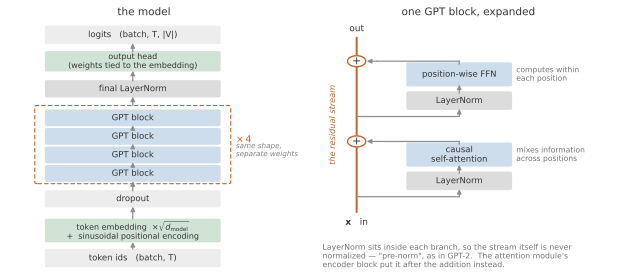

In [6]:
# the architecture, on its own: the whole model, and one block opened up
from matplotlib.patches import Circle

NORM = '#dcdcdc'


def gpt_architecture_figure():
    fig, (axL, axR) = plt.subplots(1, 2, figsize=(9, 4),
                                   gridspec_kw={'width_ratios': [1, 1.1]})

    def box(ax, xc, yc, w, h, label, fc, fs=8.5):
        ax.add_patch(FancyBboxPatch((xc - w / 2, yc - h / 2), w, h,
                                    boxstyle='round,pad=0.12', facecolor=fc,
                                    edgecolor='none'))
        ax.text(xc, yc, label, ha='center', va='center', fontsize=fs, color=TX)

    def arrow(ax, x0, y0, x1, y1, color='0.55', lw=1.2):
        ax.add_patch(FancyArrowPatch((x0, y0), (x1, y1), arrowstyle='-|>',
                                     mutation_scale=9, color=color, linewidth=lw,
                                     shrinkA=0, shrinkB=0, zorder=2))

    # ------------------------- left: the whole model ----------------------
    W, X = 7.6, 0.0
    box(axL, X, 0.0, W, 1.5, 'token ids   (batch, T)', IO)
    arrow(axL, X, 0.85, X, 1.5)
    box(axL, X, 2.6, W, 2.0, 'token embedding  '
        + r'$\times \sqrt{d_{\mathrm{model}}}$'
        + '\n+  sinusoidal positional encoding', GREEN, 8.0)
    arrow(axL, X, 3.7, X, 4.85)
    box(axL, X, 5.6, W, 1.4, 'dropout', IO)
    arrow(axL, X, 6.35, X, 7.25)

    for k in range(4):
        y = 8.0 + k * 1.75
        box(axL, X, y, W, 1.35, 'GPT block', BLUE)
        if k < 3:
            arrow(axL, X, y + 0.7, X, y + 1.05)
    axL.add_patch(FancyBboxPatch((X - W / 2 - 0.45, 7.15), W + 0.9, 7.15,
                                 boxstyle='round,pad=0.12', facecolor='none',
                                 edgecolor=AMBER, linewidth=1.1,
                                 linestyle=(0, (4, 2))))
    axL.text(X + W / 2 + 0.8, 11.2, r'$\times\,4$', ha='left', va='center',
             fontsize=9.5, color=AMBER)
    axL.text(X + W / 2 + 0.8, 10.2, 'same shape,\nseparate weights', ha='left',
             va='center', fontsize=7.2, color='0.5', style='italic')

    arrow(axL, X, 14.45, X, 15.25)
    box(axL, X, 16.0, W, 1.4, 'final LayerNorm', NORM)
    arrow(axL, X, 16.75, X, 17.7)
    box(axL, X, 18.6, W, 1.7,
        'output head\n(weights tied to the embedding)', GREEN, 8.0)
    arrow(axL, X, 19.5, X, 20.3)
    box(axL, X, 21.1, W, 1.5, 'logits   (batch, T, |V|)', IO)

    axL.set_xlim(-5.6, 6.6); axL.set_ylim(-1.4, 22.4)
    axL.axis('off')
    axL.set_title('the model', fontsize=10.5, color=TX)

    # ------------------------- right: one block ---------------------------
    SX, BX = -2.9, 1.6          # the residual stream, and the sublayer branch
    axR.plot([SX, SX], [-0.2, 12.4], color=AMBER, lw=2.0,
             solid_capstyle='round', zorder=1)
    axR.text(SX, -0.95, r'$\mathbf{x}$   in', ha='center', va='center',
             fontsize=9, color=TX)
    axR.text(SX - 1.05, 6.1, 'the residual stream', rotation=90, ha='center',
             va='center', fontsize=8.2, style='italic', color=AMBER)
    axR.text(SX, 13.05, 'out', ha='center', va='center', fontsize=9, color=TX)

    def sublayer(y0, label, note):
        """A pre-norm sublayer: leave the stream at y0, rejoin it at y0 + 4."""
        y_join = y0 + 4.0
        axR.plot([SX, BX], [y0, y0], color='0.55', lw=1.2, zorder=2)
        arrow(axR, BX, y0, BX, y0 + 0.55)
        box(axR, BX, y0 + 1.15, 4.4, 1.1, 'LayerNorm', NORM)
        arrow(axR, BX, y0 + 1.7, BX, y0 + 2.3)
        box(axR, BX, y0 + 3.05, 4.4, 1.5, label, BLUE)
        axR.plot([BX, BX], [y0 + 3.8, y_join], color='0.55', lw=1.2, zorder=2)
        axR.plot([BX, SX + 0.9], [y_join, y_join], color='0.55', lw=1.2, zorder=2)
        arrow(axR, SX + 0.9, y_join, SX + 0.45, y_join)
        axR.add_patch(Circle((SX, y_join), 0.4, facecolor='white',
                             edgecolor=AMBER, linewidth=1.4, zorder=5))
        axR.text(SX, y_join, '+', ha='center', va='center', fontsize=11,
                 zorder=6, color=TX)
        axR.text(BX + 2.5, y0 + 3.05, note, ha='left', va='center', fontsize=7.6,
                 color='0.45')

    sublayer(0.9, 'causal\nself-attention', 'mixes information\nacross positions')
    sublayer(6.7, 'position-wise FFN', 'computes within\neach position')

    axR.text(-4.4, -2.5,
             'LayerNorm sits inside each branch, so the stream itself is never\n'
             'normalized — "pre-norm", as in GPT-2.  The attention module\'s\n'
             'encoder block put it after the addition instead.',
             ha='left', va='top', fontsize=7.8, color='0.45')

    axR.set_xlim(-4.6, 8.6); axR.set_ylim(-4.6, 13.6)
    axR.axis('off')
    axR.set_title('one GPT block, expanded', fontsize=10.5, color=TX)
    fig.tight_layout()


gpt_architecture_figure()

Two things in the right-hand panel are worth dwelling on.

The residual stream runs unbroken from the embedding to the final LayerNorm.  Each sublayer *branches off* it, normalizes a copy, computes, and adds the result back; nothing on the stream itself is ever normalized or overwritten.  Compare the attention module's encoder block, where the normalization sat *on* the stream, after every addition: there the clean identity path of that notebook's Jacobian was interrupted once per sublayer, and the deeper the stack the more that matters.  Here it is uninterrupted, which is what lets pre-norm models train at depth without a carefully tuned warmup.

That also explains a line in the code below that would otherwise look arbitrary.  Because no sublayer normalizes the stream, the vector arriving at the top carries the accumulated magnitude of every block that wrote to it, so a **final LayerNorm** is needed before the output head reads it.  Post-norm architectures get that for free and do not have one.

Side by side with the post-norm block of the original transformer (and GPT-1), the difference is where LayerNorm sits:

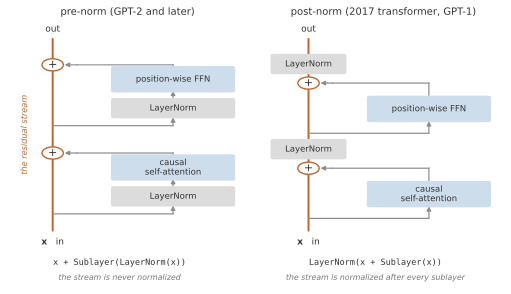

In [7]:
# pre-norm (our GPT block) next to post-norm (the original transformer's block)
def pre_vs_post_norm_figure():
    fig, axes = plt.subplots(1, 2, figsize=(7.2, 4.2))
    SX, BX = -2.9, 1.6          # the residual stream, and the sublayer branch

    def box(ax, xc, yc, w, h, label, fc, fs=8.5):
        ax.add_patch(FancyBboxPatch((xc - w / 2, yc - h / 2), w, h,
                                    boxstyle='round,pad=0.12', facecolor=fc,
                                    edgecolor='none', zorder=4))
        ax.text(xc, yc, label, ha='center', va='center', fontsize=fs,
                color=TX, zorder=5)

    def arrow(ax, x0, y0, x1, y1, color='0.55', lw=1.2):
        ax.add_patch(FancyArrowPatch((x0, y0), (x1, y1), arrowstyle='-|>',
                                     mutation_scale=9, color=color, linewidth=lw,
                                     shrinkA=0, shrinkB=0, zorder=2))

    def plus(ax, y):
        ax.add_patch(Circle((SX, y), 0.4, facecolor='white', edgecolor=AMBER,
                            linewidth=1.4, zorder=5))
        ax.text(SX, y, '+', ha='center', va='center', fontsize=11, zorder=6,
                color=TX)

    def rejoin(ax, y_top, y_join):
        """Come down the branch from y_top and add into the stream at y_join."""
        ax.plot([BX, BX], [y_top, y_join], color='0.55', lw=1.2, zorder=2)
        ax.plot([BX, SX + 0.9], [y_join, y_join], color='0.55', lw=1.2, zorder=2)
        arrow(ax, SX + 0.9, y_join, SX + 0.45, y_join)
        plus(ax, y_join)

    def frame(ax, title, formula, note, label_stream):
        ax.plot([SX, SX], [-0.2, 12.4], color=AMBER, lw=2.0,
                solid_capstyle='round', zorder=1)
        ax.text(SX, -0.95, r'$\mathbf{x}$   in', ha='center', va='center',
                fontsize=9, color=TX)
        ax.text(SX, 13.05, 'out', ha='center', va='center', fontsize=9, color=TX)
        if label_stream:
            ax.text(SX - 1.05, 6.1, 'the residual stream', rotation=90,
                    ha='center', va='center', fontsize=8.2, style='italic',
                    color=AMBER)
        ax.text(-0.4, -2.3, formula, ha='center', va='center', fontsize=8.5,
                family='monospace', color=TX)
        ax.text(-0.4, -3.3, note, ha='center', va='center', fontsize=7.8,
                style='italic', color='0.45')
        ax.set_xlim(-4.6, 4.4); ax.set_ylim(-3.9, 13.6)
        ax.axis('off')
        ax.set_title(title, fontsize=10, color=TX)

    # ---------------- left: pre-norm, LayerNorm inside each branch ----------
    ax = axes[0]
    frame(ax, 'pre-norm (GPT-2 and later)', 'x + Sublayer(LayerNorm(x))',
          'the stream is never normalized', label_stream=True)
    for y0, label in [(0.9, 'causal\nself-attention'),
                      (6.7, 'position-wise FFN')]:
        ax.plot([SX, BX], [y0, y0], color='0.55', lw=1.2, zorder=2)
        arrow(ax, BX, y0, BX, y0 + 0.55)
        box(ax, BX, y0 + 1.15, 4.4, 1.1, 'LayerNorm', NORM)
        arrow(ax, BX, y0 + 1.7, BX, y0 + 2.3)
        box(ax, BX, y0 + 3.05, 4.4, 1.5, label, BLUE)
        rejoin(ax, y0 + 3.8, y0 + 4.0)

    # ---------------- right: post-norm, LayerNorm on the stream -------------
    ax = axes[1]
    frame(ax, 'post-norm (2017 transformer, GPT-1)', 'LayerNorm(x + Sublayer(x))',
          'the stream is normalized after every sublayer', label_stream=False)
    for y0, label in [(0.6, 'causal\nself-attention'),
                      (6.2, 'position-wise FFN')]:
        ax.plot([SX, BX], [y0, y0], color='0.55', lw=1.2, zorder=2)
        arrow(ax, BX, y0, BX, y0 + 0.8)
        box(ax, BX, y0 + 1.6, 4.4, 1.5, label, BLUE)
        rejoin(ax, y0 + 2.35, y0 + 3.3)
        box(ax, SX, y0 + 4.55, 2.6, 1.1, 'LayerNorm', NORM)   # sits on the stream

    fig.tight_layout()


pre_vs_post_norm_figure()

In [8]:
class CausalSelfAttention(nn.Module):
    """The attention module's MultiHeadAttention, plus a causal mask.

    Only `forward` differs from the version we built for the classifier: the
    scores for future positions are set to -inf before the softmax."""
    def __init__(self, num_hiddens, num_heads, dropout=0.0, bias=True):
        super().__init__()
        assert num_hiddens % num_heads == 0
        self.num_heads = num_heads
        self.W_q = nn.Linear(num_hiddens, num_hiddens, bias=bias)
        self.W_k = nn.Linear(num_hiddens, num_hiddens, bias=bias)
        self.W_v = nn.Linear(num_hiddens, num_hiddens, bias=bias)
        self.W_o = nn.Linear(num_hiddens, num_hiddens, bias=bias)
        self.attn_dropout = nn.Dropout(dropout)
        self.resid_dropout = nn.Dropout(dropout)

    def split_heads(self, X):
        b, seq, _ = X.shape
        return X.reshape(b, seq, self.num_heads, -1).transpose(1, 2)

    def merge_heads(self, X):
        b, h, seq, d_head = X.shape
        return X.transpose(1, 2).reshape(b, seq, h * d_head)

    def forward(self, X):
        Q = self.split_heads(self.W_q(X))          # (batch, heads, seq, d_head)
        K = self.split_heads(self.W_k(X))
        V = self.split_heads(self.W_v(X))

        d = Q.shape[-1]
        scores = Q @ K.transpose(-2, -1) / math.sqrt(d)   # (b, h, seq, seq)
        # --- the causal mask: forbid attending to later positions ---
        seq = X.shape[1]
        future = torch.triu(torch.ones(seq, seq, dtype=torch.bool,
                                       device=X.device), diagonal=1)
        scores = scores.masked_fill(future, float('-inf'))
        # ------------------------------------------------------------
        self.attention_weights = F.softmax(scores, dim=-1)
        out = self.attn_dropout(self.attention_weights) @ V
        return self.resid_dropout(self.W_o(self.merge_heads(out)))

**A note about computing masked attention.**
The code segment that implements masking uses a neat trick:
`torch.triu` with `diagonal=1` marks the entries
strictly above the diagonal, the future of each query; the diagonal itself is
not masked, so every token can attend to itself.  Setting those scores to
$-\infty$ makes their softmax weights exactly $0$, since $e^{-\infty} = 0$, and
each row is normalized over the positions that remain: row $t$ is a
probability distribution over tokens $0, \dots, t$.
This is illustrated in the following figure:

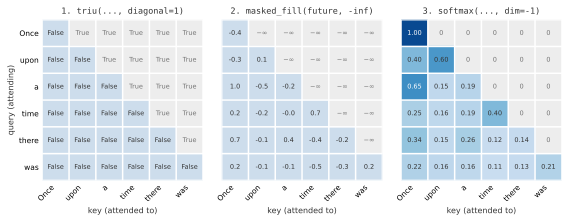

In [9]:
# what the three lines of the causal mask do, on six positions
def causal_mask_figure(scores, words):
    """Three panels: the mask, the masked scores, and the attention weights."""
    T = len(words)
    future = np.triu(np.ones((T, T), dtype=bool), k=1)
    masked = np.where(future, -np.inf, scores)
    weights = np.exp(masked - masked.max(axis=1, keepdims=True))
    weights = weights / weights.sum(axis=1, keepdims=True)

    fig, axes = plt.subplots(1, 3, figsize=(8, 3.1))
    titles = ['1. triu(..., diagonal=1)',
              '2. masked_fill(future, -inf)',
              '3. softmax(..., dim=-1)']

    for k, (ax, title) in enumerate(zip(axes, titles)):
        # background: masked cells gray, allowed cells blue (panel 3: shaded by weight)
        image = np.zeros((T, T, 3))
        for i in range(T):
            for j in range(T):
                if future[i, j]:
                    color = IO
                elif k == 2:
                    color = plt.cm.Blues(0.15 + 0.75 * weights[i, j])
                else:
                    color = BLUE
                image[i, j] = matplotlib.colors.to_rgb(color)
        ax.imshow(image)

        # cell text
        for i in range(T):
            for j in range(T):
                if k == 0:
                    text = 'True' if future[i, j] else 'False'
                elif k == 1:
                    text = '−∞' if future[i, j] else f'{scores[i, j]:.1f}'
                else:
                    text = '0' if future[i, j] else f'{weights[i, j]:.2f}'
                dark = k == 2 and not future[i, j] and weights[i, j] > 0.6
                ax.text(j, i, text, ha='center', va='center', fontsize=6.5,
                        color='white' if dark else (TX if not future[i, j] else '0.45'))

        # thin white grid lines between cells
        ax.set_xticks(np.arange(-0.5, T), minor=True)
        ax.set_yticks(np.arange(-0.5, T), minor=True)
        ax.grid(which='minor', color='white', linewidth=1.5)
        ax.tick_params(which='minor', length=0)
        for spine in ax.spines.values():
            spine.set_visible(False)

        ax.set_xticks(range(T))
        ax.set_xticklabels(words, rotation=45, ha='right', fontsize=7.5)
        ax.set_yticks(range(T))
        ax.set_yticklabels(words if k == 0 else [], fontsize=7.5)
        ax.tick_params(which='major', length=0)
        ax.set_title(title, fontsize=8.5, family='monospace', color=TX)
        ax.set_xlabel('key (attended to)', fontsize=8, color=TX)

    axes[0].set_ylabel('query (attending)', fontsize=8, color=TX)
    plt.tight_layout()


# real scores from one head of an untrained attention module, six positions
# labeled with the words of a short phrase
import matplotlib
torch.manual_seed(0)
demo = CausalSelfAttention(32, 4).eval()
X_demo = torch.randn(1, 6, 32)
with torch.no_grad():
    Q = demo.split_heads(demo.W_q(X_demo))
    K = demo.split_heads(demo.W_k(X_demo))
    demo_scores = (Q @ K.transpose(-2, -1) / math.sqrt(Q.shape[-1]))[0, 0]

causal_mask_figure(demo_scores.numpy(),
                   ['Once', 'upon', 'a', 'time', 'there', 'was'])

In [10]:
# Does the mask actually work?
torch.manual_seed(0)
att = CausalSelfAttention(32, 4).eval()
X = torch.randn(1, 6, 32)

W = att(X) is not None and att.attention_weights[0, 0]
print('attention weights, head 0 (rows = queries, cols = keys):')
print(W.detach().round(decimals=2).numpy())
assert torch.allclose(W.triu(1), torch.zeros_like(W)), 'attends to the future!'
assert torch.allclose(W.sum(-1), torch.ones(6)), 'rows must be distributions'

# The decisive test: changing a LATER token must not change an EARLIER output.
X2 = X.clone()
X2[0, 4] = torch.randn(32)                    # perturb position 4
out1, out2 = att(X), att(X2)
print(f'\nmax change at positions 0-3: {(out1[0, :4] - out2[0, :4]).abs().max():.2e}')
print(f'max change at positions 4-5: {(out1[0, 4:] - out2[0, 4:]).abs().max():.2e}')
assert torch.allclose(out1[0, :4], out2[0, :4], atol=1e-6)
print('\ncausal masking verified: no information flows backwards in time')

attention weights, head 0 (rows = queries, cols = keys):
[[1.   0.   0.   0.   0.   0.  ]
 [0.4  0.6  0.   0.   0.   0.  ]
 [0.65 0.15 0.19 0.   0.   0.  ]
 [0.25 0.16 0.19 0.4  0.   0.  ]
 [0.34 0.15 0.26 0.12 0.14 0.  ]
 [0.22 0.16 0.16 0.11 0.13 0.21]]

max change at positions 0-3: 0.00e+00
max change at positions 4-5: 2.00e-01

causal masking verified: no information flows backwards in time


That second test is interesting when writing an autoregressive model: perturb a token and confirm that *earlier* outputs are unchanged.  A subtly broken mask leaks the answer into the question; training loss goes down, while generation is gibberish.

Now the block and the full model.

In [11]:
class PositionWiseFFN(nn.Module):
    """The attention module's FFN, with GELU in place of ReLU (as in GPT-2)."""
    def __init__(self, num_hiddens, ffn_num_hiddens, dropout=0.0):
        super().__init__()
        self.dense1 = nn.Linear(num_hiddens, ffn_num_hiddens)
        self.dense2 = nn.Linear(ffn_num_hiddens, num_hiddens)
        self.dropout = nn.Dropout(dropout)

    def forward(self, X):
        return self.dropout(self.dense2(F.gelu(self.dense1(X))))


class GPTBlock(nn.Module):
    """A decoder block: causal self-attention + FFN, both pre-normalized.

    Compare the attention module's encoder block, which was post-norm:
        Y = LayerNorm(X + Attention(X));  return LayerNorm(Y + FFN(Y))"""
    def __init__(self, num_hiddens, ffn_num_hiddens, num_heads, dropout):
        super().__init__()
        self.ln1 = nn.LayerNorm(num_hiddens)
        self.attention = CausalSelfAttention(num_hiddens, num_heads, dropout)
        self.ln2 = nn.LayerNorm(num_hiddens)
        self.ffn = PositionWiseFFN(num_hiddens, ffn_num_hiddens, dropout)

    def forward(self, X):
        X = X + self.attention(self.ln1(X))    # residual path stays un-normalized
        return X + self.ffn(self.ln2(X))


class PositionalEncoding(nn.Module):
    """The attention module's sinusoidal positional encoding, unchanged."""
    def __init__(self, d_model, max_len=5000):
        super().__init__()
        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len, dtype=torch.float).unsqueeze(1)
        div_term = torch.exp(torch.arange(0, d_model, 2).float()
                             * (-math.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        self.register_buffer('pe', pe.unsqueeze(0))

    def forward(self, X):
        return X + self.pe[:, :X.size(1), :]

In [12]:
class GPT(nn.Module):
    """A decoder-only transformer language model."""
    def __init__(self, vocab_size, num_hiddens=256, ffn_num_hiddens=1024,
                 num_heads=8, num_blks=4, dropout=0.1, max_len=CONTEXT):
        super().__init__()
        self.num_hiddens = num_hiddens
        self.embedding = nn.Embedding(vocab_size, num_hiddens)
        self.pos_encoding = PositionalEncoding(num_hiddens, max_len)
        self.dropout = nn.Dropout(dropout)
        self.blks = nn.ModuleList([
            GPTBlock(num_hiddens, ffn_num_hiddens, num_heads, dropout)
            for _ in range(num_blks)])
        self.ln_f = nn.LayerNorm(num_hiddens)          # final norm (pre-norm nets need it)
        self.lm_head = nn.Linear(num_hiddens, vocab_size, bias=False)
        self.lm_head.weight = self.embedding.weight    # weight tying
        self.apply(self._init_weights)

    def _init_weights(self, m):
        if isinstance(m, nn.Linear):
            nn.init.normal_(m.weight, std=0.02)        # GPT-2's initialization
            if m.bias is not None:
                nn.init.zeros_(m.bias)
        elif isinstance(m, nn.Embedding):
            nn.init.normal_(m.weight, std=0.02)

    def forward(self, X, targets=None):
        H = self.pos_encoding(self.embedding(X) * math.sqrt(self.num_hiddens))
        H = self.dropout(H)
        for blk in self.blks:
            H = blk(H)
        logits = self.lm_head(self.ln_f(H))            # (batch, seq, vocab)
        if targets is None:
            return logits, None
        loss = F.cross_entropy(logits.reshape(-1, logits.size(-1)),
                               targets.reshape(-1))
        return logits, loss

model = GPT(VOCAB_SIZE).to(device)
n_params = sum(p.numel() for p in model.parameters())
n_embed = model.embedding.weight.numel()
print(f'{n_params/1e6:.2f}M parameters '
      f'({n_embed/1e6:.2f}M in the (tied) embedding, '
      f'{(n_params-n_embed)/1e6:.2f}M in the blocks)')

4.21M parameters (1.05M in the (tied) embedding, 3.16M in the blocks)


### Sanity checks before training

Training a broken model wastes an hour and teaches nothing, so we spend a minute on two checks that catch most bugs (the causal-mask test above was the third).

The first is the most useful diagnostic in language modeling: **an untrained model must have perplexity $\approx |V|$**.  Random weights mean a near-uniform softmax, and notebook 2 fixed that anchor — uniform guessing over $|V|$ options costs exactly $\ln |V|$ nats.  If your initial loss is far from $\ln|V|$, something is wrong before you start (a common culprit: initialization at the wrong scale).

In [13]:
model.eval()
with torch.no_grad():
    xb, yb = get_batch(val_ids, 8)
    logits, loss = model(xb, yb)

print(f'output shape {tuple(logits.shape)} = (batch, context, vocab)')
print(f'initial loss       {loss.item():.3f} nats')
print(f'ln(vocab_size)     {math.log(VOCAB_SIZE):.3f} nats   <- expected at random init')
print(f'initial perplexity {math.exp(loss.item()):.0f}  (vocabulary = {VOCAB_SIZE})')

# 2. Can it overfit a single batch?  If not, the training loop is broken.
#    (A short context and a high learning rate keep this to well under a minute.)
probe = GPT(VOCAB_SIZE).to(device)
opt = torch.optim.AdamW(probe.parameters(), lr=1e-3)
xb, yb = get_batch(train_ids, 4, context=64)
probe.train()
for step in range(300):
    _, l = probe(xb, yb)
    opt.zero_grad(); l.backward(); opt.step()
    if step % 100 == 0:
        print(f'  overfit probe, step {step:3d}: loss {l.item():.3f}')
print(f'after 300 steps on ONE batch: loss {l.item():.3f} '
      f'(should approach 0 -- the model can memorize)')
del probe, opt

output shape (8, 256, 4096) = (batch, context, vocab)
initial loss       8.377 nats
ln(vocab_size)     8.318 nats   <- expected at random init
initial perplexity 4347  (vocabulary = 4096)
  overfit probe, step   0: loss 8.392
  overfit probe, step 100: loss 0.022
  overfit probe, step 200: loss 0.007
after 300 steps on ONE batch: loss 0.004 (should approach 0 -- the model can memorize)


Both checks pass: the model starts as ignorant as theory says it must, and it *can* learn when the gradient path is intact.  The single-batch overfit test is worth internalizing — a model that cannot memorize four sequences will never learn four million, and the failure is almost always a wiring bug rather than a hyperparameter.

## Training

The loop holds no surprises beyond what the attention module already used, plus two standard refinements:

* **AdamW with weight decay**, applied only to weight matrices; biases and LayerNorm gains are excluded, since shrinking them toward zero has no regularizing benefit.
* **A cosine learning-rate schedule with a short warmup**: ramp up over the first few hundred steps, then decay smoothly toward zero.  (You saw warmup + linear decay in the BERT fine-tuning notebook; cosine decay is the standard for pretraining.)  Pre-norm makes warmup optional rather than essential, but it still helps.

We also evaluate periodically on held-out data — reporting **perplexity**, and sample a short story at each evaluation, so the model's progress is legible as text.

In [14]:
@torch.no_grad()
def estimate_loss(model, data, n_batches=20, batch_size=32):
    model.eval()
    g = torch.Generator().manual_seed(1234)          # same windows every time
    total = 0.0
    for _ in range(n_batches):
        xb, yb = get_batch(data, batch_size, generator=g)
        total += model(xb, yb)[1].item()
    model.train()
    return total / n_batches


@torch.no_grad()
def generate(model, prompt='Once upon a time', max_new_tokens=100,
             temperature=0.8, top_k=None, seed=None):
    """Autoregressive sampling -- notebook 1's loop, now with temperature."""
    model.eval()
    # Seeding makes samples reproducible.  We save and restore the global RNG
    # state around it: otherwise calling this from inside the training loop
    # would reset the RNG and make every batch after an eval identical.
    rng_state = torch.get_rng_state()
    if seed is not None:
        torch.manual_seed(seed)          # works on cpu, cuda and mps alike
    ids = torch.tensor([tokenizer.encode(prompt).ids], device=device)
    for _ in range(max_new_tokens):
        logits, _ = model(ids[:, -CONTEXT:])          # never exceed the context
        logits = logits[:, -1, :] / temperature       # <1 sharpens, >1 flattens
        if top_k is not None:
            kth = logits.topk(top_k, dim=-1).values[:, [-1]]
            logits = logits.masked_fill(logits < kth, float('-inf'))
        nxt = torch.multinomial(logits.softmax(-1), 1)
        if nxt.item() == EOT:
            break
        ids = torch.cat([ids, nxt], dim=1)
    model.train()
    torch.set_rng_state(rng_state)
    return tokenizer.decode(ids[0].tolist())

In [15]:
MAX_STEPS = 3000          # ~10 min on Apple MPS, ~40 min on CPU; 6000+ is better
BATCH_SIZE = 32
EVAL_EVERY = 250
WARMUP, LR, MIN_LR = 200, 3e-4, 3e-5

def lr_at(step):
    if step < WARMUP:                                   # linear warmup
        return LR * (step + 1) / WARMUP
    progress = (step - WARMUP) / max(1, MAX_STEPS - WARMUP)
    return MIN_LR + 0.5 * (LR - MIN_LR) * (1 + math.cos(math.pi * progress))

decay = [p for p in model.parameters() if p.dim() >= 2]   # matrices
no_decay = [p for p in model.parameters() if p.dim() < 2]  # biases, LayerNorm
opt = torch.optim.AdamW([{'params': decay, 'weight_decay': 0.1},
                         {'params': no_decay, 'weight_decay': 0.0}],
                        lr=LR, betas=(0.9, 0.95))

history = []
t0 = time.time()
model.train()
for step in range(MAX_STEPS + 1):
    for group in opt.param_groups:
        group['lr'] = lr_at(step)

    xb, yb = get_batch(train_ids, BATCH_SIZE)
    _, loss = model(xb, yb)
    opt.zero_grad(set_to_none=True)
    loss.backward()
    torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)   # guards against spikes
    opt.step()

    if step % EVAL_EVERY == 0:
        tr, va = estimate_loss(model, train_ids), estimate_loss(model, val_ids)
        history.append((step, math.exp(tr), math.exp(va)))
        print(f'step {step:5d} | train PPL {math.exp(tr):7.1f} | '
              f'val PPL {math.exp(va):7.1f} | {time.time() - t0:5.0f}s')
        print(f'   {generate(model, max_new_tokens=40, seed=0)!r}\n')

tokens_seen = MAX_STEPS * BATCH_SIZE * CONTEXT
print(f'done in {(time.time() - t0)/60:.1f} min; '
      f'{tokens_seen/1e6:.1f}M tokens seen '
      f'({tokens_seen/len(train_ids):.1f} epochs over the corpus)')

step     0 | train PPL  4331.5 | val PPL  4323.9 |     5s
   'Once upon a time swam Ducky when monster moms nods covered eating prize sunshine elderlyJill someady best blow� see neckl sing foolish worryely blfort bandage yach cross falls needs scooterasedctor rice valuecion become finds whenever'

step   250 | train PPL    86.2 | val PPL    80.5 |    89s
   'Once upon a time, there was a little named Lily. He\'s laughed. But there was sad.\n" sing the world.\n\n"Tom was fallsy. \n\nThey was proud more boy named I'

step   500 | train PPL    44.2 | val PPL    41.1 |   169s
   'Once upon a time, there was a little named Lily. He\'s hair. She loved to blows and ran at the world.\n\n"Wow, Lily!" Sara said, "That is more!"\n'

step   750 | train PPL    32.3 | val PPL    30.2 |   250s
   "Once upon a time, there was a little named Lily. She's mommy. One day, Lucy saw a big sing the store to rest behind some paper. Lily's car can have lots of sticks with her paint."

step  1000 | train PPL   

The printed samples are the real result of this notebook.  Read them in order and you can watch the model acquire language in stages: first token frequencies (a fog of *the*, *and*, *she*), then word-level grammar, then sentence structure and punctuation, then — remarkably, for a model this small — characters that persist across sentences and stories that actually resolve.  Nothing supervised this progression.  It is all "predict the next token", applied to enough text.

Note also *where the perplexity lands*.  Starting from $|V| = 4096$ (pure chance), a few thousand steps take it into the low tens, meaning the model has narrowed a four-thousand-way choice down to an effective handful of options at each step.

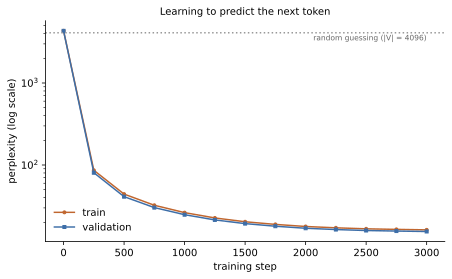

In [16]:
steps, tr, va = zip(*history)
fig, ax = plt.subplots(figsize=(6.4, 4))
ax.plot(steps, tr, 'o-', color=AMBER, label='train', markersize=3)
ax.plot(steps, va, 's-', color='#3d6ea8', label='validation', markersize=3)
ax.axhline(VOCAB_SIZE, ls=':', color='0.6')
ax.text(steps[-1], VOCAB_SIZE * 0.95, f'random guessing (|V| = {VOCAB_SIZE})',
        ha='right', va='top', fontsize=7.5, color='0.4')
ax.set_yscale('log')
ax.set_xlabel('training step'); ax.set_ylabel('perplexity (log scale)')
ax.set_title('Learning to predict the next token', fontsize=10)
ax.legend(frameon=False); ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout();

Seeing that the training and validation curves stay close together tells us that this run is **not** overfitting; unsurprising, since with a few epochs over several million tokens the model sees most text only a handful of times.  This is the normal regime for language-model pretraining, and it is the opposite of the trigram's predicament in notebook 2: that model memorized because it had one parameter per observed context, while ours is forced to *generalize* because 4M parameters cannot store millions of tokens' worth of detail.  If you scale `MAX_STEPS` up far enough on a fixed corpus, the two curves will eventually separate — the classic sign that you need more data rather than more steps.

## Talking to our model

With training done, we can explore what the model learned.  The `temperature` knob is worth playing with: it divides the logits before the softmax, so low values sharpen the distribution toward the argmax (conservative, repetitive) and high values flatten it (creative, incoherent).  The next notebook examines this in detail.

In [17]:
for temp in [0.2, 0.8, 1.4]:
    print(f'--- temperature {temp} ---')
    print(generate(model, 'Once upon a time', max_new_tokens=120,
                   temperature=temp, seed=0), '\n')

print('--- prompted continuations (temperature 0.8) ---')
for prompt in ['Lily found a big red ball. She',
               'The dragon was very sad because',
               'Tom and his mother went to the park to']:
    print(f'{generate(model, prompt, max_new_tokens=80, seed=1)}\n')

--- temperature 0.2 ---
Once upon a time, there was a little girl named Lily. She loved to play with her toys and play with her toys. One day, she saw a big box in the box. She wanted to see what was inside.

"What is this?" asked Lily.

"I want to see what is?" Lily asked.

"I want to see the box," said Lily.

"I want to see the box," Lily said. "But it is too high. It is too high. It is too fast. It is too fast and cold. It is not a big 

--- temperature 0.8 ---
Once upon a time, there was a little girl named Lily. She loved playing in the park with her friends. One day, she met a boy named Timmy. Timmy was always so happy and proud of her friends.

One day, Max met a young cat named Max. She decided to draw some ice cream and some flowers. Her friends went up to a big zoo and saw that was black and sharp and fl bread. Lily nodded and said, "Don't worry, Max! I am very dirty!" 

From that day on, Max went outside the park and saw that Lily was so excited. 

--- temperature 1.4 ---
On

Low temperature gives safe, repetitive prose; high temperature loses the thread; around 0.8 tends to read best — the same tradeoff practitioners tune for every deployed model.

This model writes fluent, mostly-grammatical children's stories, and that is a real achievement for 6M parameters and a few minutes of laptop compute.  But it knows nothing outside this corpus: it cannot answer questions, follow instructions, or discuss anything but simple stories, because its entire experience of language is 40,000 synthetic children's tales.  Capability follows data and scale, exactly as notebook 1's scaling laws describe.

## How to scale up LLMs

Our model is a faithful miniature, but the gap to a modern LLM is not only size.  To grow this by orders of magnitude, these are some of the pieces that make that more feasible:

* **Positional encoding.**  Sinusoids are fine here; modern models use **RoPE** (rotary embeddings), which encodes *relative* position by rotating Q and K, and extrapolates better to longer contexts than the model was trained on.
* **Normalization and activation.**  **RMSNorm** (LayerNorm without the mean subtraction) is cheaper and works as well; **SwiGLU** replaces our GELU FFN with a gated variant that is consistently a little better per parameter.
* **KV cache.** Our `generate` function runs the entire context through the model to produce each new token, recomputing the keys and values of every earlier token at every step. Because of the causal mask, those keys and values never change once computed: a token’s representation depends only on the tokens before it. A KV cache stores them, so each step computes Q, K and V for the new token only and attends to the cached K and V. The work per generated token drops from a forward pass over the whole context to a forward pass over one token. The cost is memory: the cache holds a key and a value vector for every token, in every layer and every head, so it grows linearly with context length and is often the main memory cost of serving long contexts. **Grouped-query attention** shrinks it by letting several query heads share one key/value head.
* **Attention efficiency.**  Our code which explicitly computes the $T \times T$ attention matrix costs $O(T^2)$ memory. **FlashAttention** gets the identical result with $O(T)$ memory: it processes the keys in blocks and keeps a running softmax, so the full matrix never exists. The arithmetic is still $O(T^2)$, but on a GPU memory traffic is the bottleneck, so it is also much faster.
* **Precision and parallelism.**  bfloat16 mixed precision, gradient accumulation for large effective batches, and — past a single machine — data and tensor parallelism across many GPUs.
* **Data, above all.**  Trillions of tokens of filtered, deduplicated, diverse text.  This is where most of the real work in frontier pretraining goes, and it is the element that separates a story-teller from an assistant.

We have now been through the entire pretraining half of the pipeline: architecture, objective, tokenizer, training loop, evaluation.  In the next notebook we pick up models where trillions of tokens have already been spent and find out what that buys.

## Summary

* **TinyStories** makes small-scale language modeling instructive: a corpus simple enough that a ~6M-parameter model trained for minutes produces coherent, grammatical prose.
* Our **GPT** is the attention module's transformer with three changes: a **causal mask** (three lines), **pre-norm** blocks (better gradient flow in deep stacks), and **weight tying** between the embedding and the output layer.  Training data is one long token stream; a batch is a set of random windows with targets shifted by one.
* **Verify before training**: initial loss must be $\approx \ln |V|$; the model must be able to overfit a single batch; and perturbing a token must leave *earlier* outputs unchanged — the definitive test that the causal mask is intact.
* The training recipe is standard and small: AdamW (decay on matrices only), warmup + cosine decay, gradient clipping, periodic validation **perplexity** — which falls from $|V|$ to the low tens while the samples progress from noise to stories.
* Scaling further is a matter of engineering refinements (RoPE, RMSNorm, SwiGLU, FlashAttention, mixed precision) and, above all, **far more data** — not of new architectural ideas.

## Exercises

1. **Break the mask on purpose.**  Delete the `masked_fill` line, retrain for a few hundred steps, and compare the loss curve to the correct model.  Why does the loss collapse toward zero, and why is the resulting model useless for generation?  Which of the three sanity checks catches this bug, and which do not?

2. **Verify the shift.**  Take one batch from `get_batch` and confirm by hand that `y[i][t] == x[i][t+1]` for every valid `t`, and that both come from the same contiguous stretch of the corpus.  Then break it deliberately (use `y = x`) and predict, before running, what the model would learn.

3. **Context length.**  Train with `CONTEXT` set to 64 and to 512 (adjusting `BATCH_SIZE` to keep memory roughly constant).  Compare final validation perplexity, wall-clock time per step, and — most importantly — the *coherence* of generated stories.  Where is the tradeoff, and why does attention cost grow quadratically in context?

4. **Width versus depth.**  With the parameter count held roughly fixed, compare a wide-shallow model (`num_hiddens=384, num_blks=2`) against a narrow-deep one (`num_hiddens=192, num_blks=8`).  Which wins on validation perplexity, and does the answer change with more training steps?

5. **Vocabulary size.**  Retrain the tokenizer with `vocab_size` 1024 and 16384 and rerun training.  Track three things: parameter count, tokens per story, and validation perplexity — then explain why the perplexities are *not directly comparable* across the three runs (notebook 2 gives the reason), and compute a comparison that is fair.

6. **Sampling strategy.**  Generate with `temperature` in {0.1, 0.5, 1.0, 2.0} at a fixed seed, and separately with `top_k` in {1, 5, 50, None}.  Characterize the failure mode at each extreme.  Which combination would you ship, and what does "best" mean here — lowest perplexity, or something perplexity cannot measure?

7. **Watch the attention.**  Every block stores `attention_weights`.  Pick a trained block and visualize its heads (as we did in the attention module) on a short story.  Do any heads specialize — attending to the previous token, to the start of the sentence, to a character's name?  Compare the same plot for an *untrained* model to be sure you are seeing learned structure and not the mask.

8. **The compute-optimal question.**  Compute the tokens-per-parameter ratio of your run.  How does it compare to Chinchilla's ~20?  Given a fixed budget of twice the training time, would you spend it on more steps, a bigger model, or more data — and what experiment would settle the question rather than the argument?